# The Double Gyre: Breaking the Symmetry

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jejjohnson/sesmax/blob/main/docs/notebooks/doublegyre_barotropic_qg.ipynb)

*Moved from somax's tutorial series, with another wind.*

[Step 18](step18_barotropic_qg.ipynb) spun up the barotropic double gyre for 230 days with a viscosity of 4000 m²/s, and the two gyres it drew were mirror images of each other. Here the viscosity is 150 m²/s and the run lasts eight years. The gyres start as mirror images, and after two years they are not any more: the flow settles into a state that the wind's symmetry does not explain.

**What you'll learn:**

1. Which symmetry the wind gives the double gyre, and how to measure it
2. How to run [`BarotropicQG`](xref:api#sesmax_ocean.qg.BarotropicQG) for years and watch it with its diagnostics
3. When the symmetric gyres give way, and what is left after
4. Why this run has no eddies, and which config of `sesmax-ocean` has them

## Setup

On Colab, install `sesmax-ocean`; locally, with the repository's environment, this does nothing.

In [1]:
import subprocess
import sys


try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    repository = "git+https://github.com/jejjohnson/sesmax@main#subdirectory=packages/"
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            f"sesmax-core @ {repository}sesmax-core",
            f"sesmax-ocean @ {repository}sesmax-ocean",
        ],
        check=True,
    )

## The PDE and its symmetry

The model is that of step 18, which derives it:

$$
\frac{\partial q}{\partial t} + J(\psi, q) + \beta \frac{\partial \psi}{\partial x} = -\tau_0 \sin\left(\frac{2 \pi y}{L_y}\right) - \kappa \nabla^2 \psi + \nu \nabla^2 q, \qquad \nabla^2 \psi = q
$$

Reflect the basin about its middle latitude and change the sign of the flow:

$$
\psi'(x, y) = -\psi(x, L_y - y), \qquad q'(x, y) = -q(x, L_y - y)
$$

Each term of the equation changes sign under this map: the Jacobian because it holds one derivative in $y$, the $\beta$ term and the friction because they are linear in $\psi$, and the wind because $\sin(2\pi y / L_y)$ is odd about $y = L_y / 2$. So if $\psi$ solves the equation, so does $\psi'$, and a flow that starts with $\psi' = \psi$ keeps it. The gyre in the south is then the mirror image of the one in the north, turning the other way. We measure how far a flow is from that with the asymmetry

$$
a(t) = \frac{\lVert \psi(x, y, t) + \psi(x, L_y - y, t) \rVert}{\lVert \psi(x, y, t) \rVert}
$$

which is zero for a mirror-image pair, $\sqrt{2}$ when the reflected field is unrelated to the field, and two for a field that is even about the middle latitude.

Whether a symmetric flow stays symmetric is another question: the symmetry says that the antisymmetric state exists, not that it is stable. A run that starts from rest plus a perturbation of $10^{-9}$ 1/s, too small to see, answers it.

### Symbols

The page is dimensional, in SI units.

| Symbol | Meaning | Shape |
| --- | --- | --- |
| $(x, y)$ | spatial coordinates (m) | $\mathbb{R}^2$ |
| $t$ | time (s) | $\mathbb{R}$ |
| $q(x, y, t)$ | potential vorticity anomaly (1/s) | $\mathbb{R}$ |
| $\psi(x, y, t)$ | streamfunction (m²/s) | $\mathbb{R}$ |
| $\psi'$, $q'$ | the reflected streamfunction and PV | $\mathbb{R}$ |
| $a(t)$ | asymmetry of the streamfunction | $\mathbb{R}_{\geq 0}$ |
| $J(\cdot, \cdot)$ | Jacobian | $\mathbb{R}$ |
| $\beta$ | meridional gradient of the Coriolis parameter (1/(m s)) | $\mathbb{R}_{>0}$ |
| $\tau_0$ | amplitude of the wind's curl (1/s²) | $\mathbb{R}_{>0}$ |
| $\nu$, $\kappa$ | viscosity (m²/s) and bottom drag (1/s) | $\mathbb{R}_{>0}$ |
| $\delta_M$ | Munk width (m) | $\mathbb{R}_{>0}$ |
| $L_x$, $L_y$ | domain lengths (m) | $\mathbb{R}_{>0}$ |
| $N_{\Omega_x,x}$, $N_{\Omega_x,y}$, $N_T$ | number of interior cells along $x$ and $y$, and of saved snapshots | count |
| $\Delta x$, $\Delta t$ | grid spacing (m) and time step (s) | $\mathbb{R}_{>0}$ |

In [2]:
import time

import diffrax as dfx
import einx
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt

from sesmax_ocean.qg import BarotropicQG, BarotropicQGState
from sesmax_ocean.resolution import AssertionFailedError, check_munk_width

In [3]:
import importlib.util


try:
    from IPython import get_ipython

    ipython = get_ipython()
except ImportError:
    ipython = None

if ipython is not None and importlib.util.find_spec("watermark") is not None:
    ipython.run_line_magic("load_ext", "watermark")
    ipython.run_line_magic(
        "watermark", "-v -m -p jax,equinox,diffrax,sesmax_core,sesmax_ocean"
    )
else:
    print("watermark extension not installed; skipping reproducibility readout.")

Python implementation: CPython
Python version       : 3.13.12
IPython version      : 9.10.0

jax         : 0.12.0.1
equinox     : 0.13.8
diffrax     : 0.7.2
sesmax_core : 0.3.1
sesmax_ocean: 0.0.0

Compiler    : Clang 21.1.4 
OS          : Linux
Release     : 6.8.0-1044-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 16
Architecture: 64bit



## 1. Create the model

The basin, the planet, the wind and the drag of step 18, with a viscosity 27 times smaller. That is below what [`check_munk_width`](xref:api#sesmax_ocean.resolution.check_munk_width) accepts at this grid: the Munk layer is narrower than two cells.

In [4]:
# Shapes: N_Ωx,x = N_Ωx,y = 64 interior cells

num_cells = 64
domain_length = 1.0e6
beta = 1.6e-11
viscosity = 150.0
drag = 1.0e-7
wind = 1.0e-12

# today (sesmax_ocean)
model = BarotropicQG.create(
    nx=num_cells,
    ny=num_cells,
    Lx=domain_length,
    Ly=domain_length,
    f0=1.0e-4,
    beta=beta,
    lateral_viscosity=viscosity,
    bottom_drag=drag,
    wind_amplitude=wind,
    wind_profile="doublegyre",
)
spacing = model.grid.spacing("x")
# δ_M = (ν / β)^(1/3)
munk_width = (viscosity / beta) ** (1.0 / 3.0)
print(f"Grid spacing: {spacing / 1e3:.1f} km")
print(f"Munk width:   {munk_width / 1e3:.1f} km, {munk_width / spacing:.2f} cells")

# today (sesmax_ocean): refuses a Munk layer of fewer than two cells
try:
    check_munk_width(None, model)
except AssertionFailedError as error:
    print(str(error).splitlines()[0])

Grid spacing: 15.6 km
Munk width:   21.1 km, 1.35 cells
munk_width check FAILED: delta_M/dx = 1.35 < 2.0


Step 18 measured that Arakawa's Jacobian neither creates nor destroys energy, so the run stays bounded although the boundary layer is under-resolved; what the grid cannot hold of the western boundary current is dissipated at the grid scale instead. The flow below is a property of this grid and this viscosity, and a finer grid would draw a narrower current.

## 2. Eight years from rest

The perturbation is random in the interior and zero on the ghost ring. Snapshots every ten days give 293 of them, and the time step is 1800 s.

In [5]:
# Shapes: N_T = 293 saved snapshots; G = (N_Ωx,y + 2) × (N_Ωx,x + 2) with the ghosts

year = 365.25 * 86400.0
end_time = 8.0 * year
time_step = 1800.0
# tₖ = k t₁ / (N_T − 1)
save_times = jnp.linspace(0.0, end_time, 293)  # → (N_T,)

noise = 1.0e-9 * jax.random.normal(jax.random.key(0), (num_cells, num_cells))
q0 = jnp.zeros(model.grid.shape).at[1:-1, 1:-1].set(noise)  # → G
# today (sesmax_ocean)
start = BarotropicQGState(q=q0)

started = time.perf_counter()
# today (sesmax_core, diffrax)
solution = model.integrate(  # q → N_T × G
    start,
    t0=0.0,
    t1=end_time,
    dt=time_step,
    saveat=dfx.SaveAt(ts=save_times),
    max_steps=200_000,
)
states = jax.block_until_ready(solution.ys)
elapsed = time.perf_counter() - started
# today (sesmax_ocean): the diagnostics of each snapshot
diagnostics = jax.vmap(model.diagnose)(states)

speed = jnp.sqrt(diagnostics.u**2 + diagnostics.v**2)  # → N_T × G
largest_speed = einx.max("time [y x] -> time", speed)  # → (N_T,)
# C = max |u| Δt / Δx
courant = float(jnp.max(largest_speed)) * time_step / spacing
steps = round(end_time / time_step)
print(f"{steps} steps in {elapsed:.0f} s, {elapsed / steps * 1e3:.2f} ms a step")
print(f"All finite: {bool(jnp.all(jnp.isfinite(states.q)))}")
print(
    f"Largest speed: {float(jnp.max(largest_speed)):.2f} m/s, "
    f"Courant number {courant:.2f}"
)

140256 steps in 234 s, 1.67 ms a step
All finite: True
Largest speed: 1.84 m/s, Courant number 0.21


## 3. When the symmetry breaks

On the left, the mean kinetic energy of the basin; on the right, the asymmetry $a(t)$ on a log scale. ψ lives on the corners of the cells and the walls are the corners 0 and $N$, so the reflected field is the rows from wall to wall in reverse order. While the asymmetry grows from $10^{-4}$ to $10^{-2}$, a straight line through $\log a$ gives its e-folding time.

e-folding time of the asymmetry: 69 days


Smallest asymmetry: 1.0e-05 at 0.33 years
Asymmetry passes 0.1 at:   2.00 years
Asymmetry, last four years: 0.61 to 1.34


Kinetic energy, last four years: 0.198 m²/s², varying by 1.1%
Largest speed, last four years: 1.61 m/s


Kinetic energy: 0.327 m²/s² at 2.11 years, down to 0.086 at 2.96 years


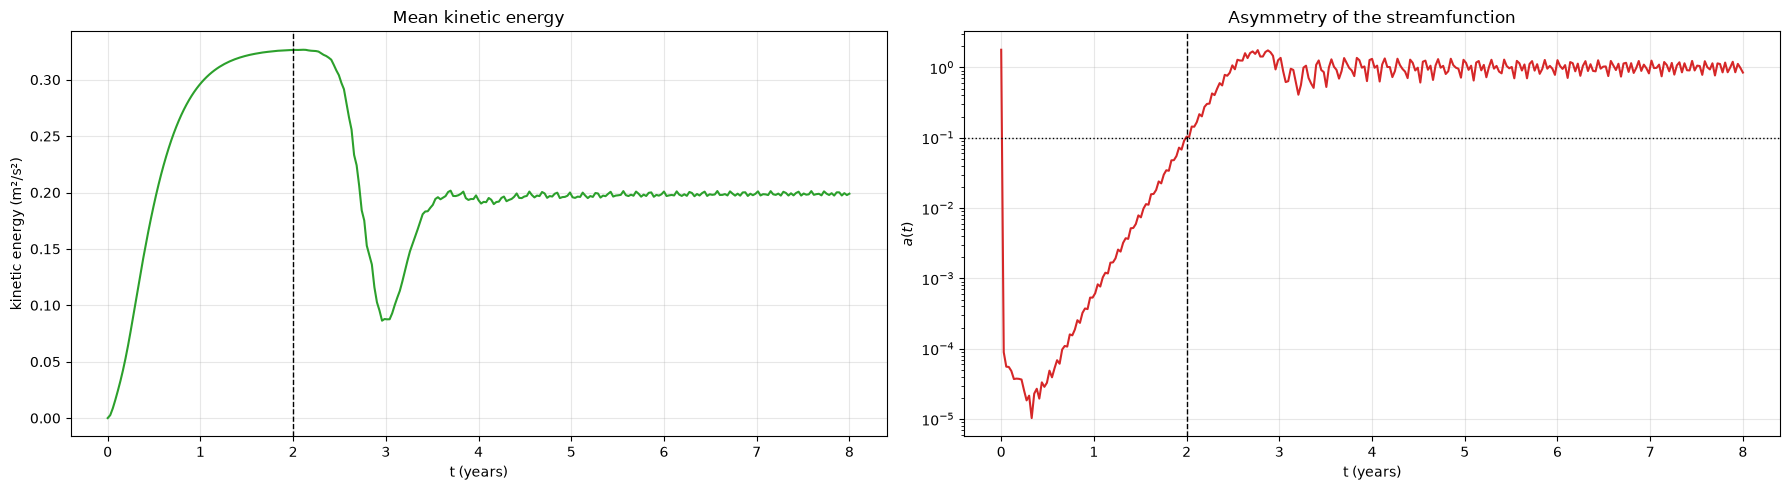

In [6]:
# Shapes: N_T = 293 saved snapshots; N_Ωx,y = N_Ωx,x = 64 interior cells

# the corners from the southern wall to the northern one, off the western wall
psi = diagnostics.psi[:, :-1, 1:-1]  # → N_T × (N_Ωx,y + 1) × N_Ωx,x
# ψ(x, L_y − y): those rows reversed
reflected = psi[:, ::-1, :]  # → N_T × (N_Ωx,y + 1) × N_Ωx,x
# a = ‖ψ + ψ(L_y − y)‖ / ‖ψ‖
mismatch = einx.sum("time [y x] -> time", (psi + reflected) ** 2)  # → (N_T,)
size = einx.sum("time [y x] -> time", psi**2)  # → (N_T,)
asymmetry = jnp.sqrt(mismatch / size)  # → (N_T,)
mean_kinetic = diagnostics.kinetic_energy / domain_length**2  # → (N_T,)
years = save_times / year  # → (N_T,)

# log a = log a₀ + t / T while a grows from 1e-4 to 1e-2
growing = (years > 0.25) & (asymmetry > 1e-4) & (asymmetry < 1e-2)
slope, _ = jnp.polyfit(years[growing], jnp.log(asymmetry[growing]), 1)
print(f"e-folding time of the asymmetry: {365.25 / float(slope):.0f} days")
# the first snapshot after the spin-up with a > 0.1
broken = int(jnp.argmax((years > 0.5) & (asymmetry > 0.1)))
late = years >= 4.0  # the last four years
late_kinetic = mean_kinetic[late]
quiet = int(jnp.argmin(jnp.where(years < 1.0, asymmetry, jnp.inf)))
print(
    f"Smallest asymmetry: {float(asymmetry[quiet]):.1e} "
    f"at {float(years[quiet]):.2f} years"
)
print(f"Asymmetry passes 0.1 at:   {float(years[broken]):.2f} years")
print(
    f"Asymmetry, last four years: {float(asymmetry[late].min()):.2f} "
    f"to {float(asymmetry[late].max()):.2f}"
)
print(
    f"Kinetic energy, last four years: {float(late_kinetic.mean()):.3f} m²/s², "
    f"varying by {float(late_kinetic.std() / late_kinetic.mean()):.1%}"
)
print(f"Largest speed, last four years: {float(largest_speed[late].max()):.2f} m/s")
peak = int(jnp.argmax(jnp.where(years < years[broken] + 0.5, mean_kinetic, -jnp.inf)))
trough = int(jnp.argmin(jnp.where(years > years[peak], mean_kinetic, jnp.inf)))
print(
    f"Kinetic energy: {float(mean_kinetic[peak]):.3f} m²/s² "
    f"at {float(years[peak]):.2f} years, "
    f"down to {float(mean_kinetic[trough]):.3f} at {float(years[trough]):.2f} years"
)

fig, axes = plt.subplots(1, 2, figsize=(18, 5))
axes[0].plot(years, mean_kinetic, color="C2")
axes[0].set_ylabel("kinetic energy (m²/s²)")
axes[0].set_title("Mean kinetic energy")
axes[1].semilogy(years, asymmetry, color="C3")
axes[1].axhline(0.1, color="k", ls=":", lw=1.0)
axes[1].set_ylabel("$a(t)$")
axes[1].set_title("Asymmetry of the streamfunction")
for ax in axes:
    ax.axvline(float(years[broken]), color="k", ls="--", lw=1.0)
    ax.set_xlabel("t (years)")
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In the first four months the wind draws two mirror-image gyres faster than the perturbation grows, and the asymmetry falls to $10^{-5}$. From there it grows by a factor $e$ every 69 days, a straight line on the log scale, until it passes 0.1 after two years. Then the gyres give way: the mean kinetic energy falls from 0.33 m²/s² at 2.1 years to 0.086 at three years, and within another year the flow settles into a state whose energy varies by 1.1 % and whose asymmetry swings between 0.6 and 1.3. The currents stay below 1.9 m/s, at a Courant number of 0.21.

## 4. Before and after

The streamfunction one year in, when the gyres are still mirror images; at the end of the run; and its mean over the last four years. The contours are the same on the three panels.

Asymmetry of the mean: 0.20


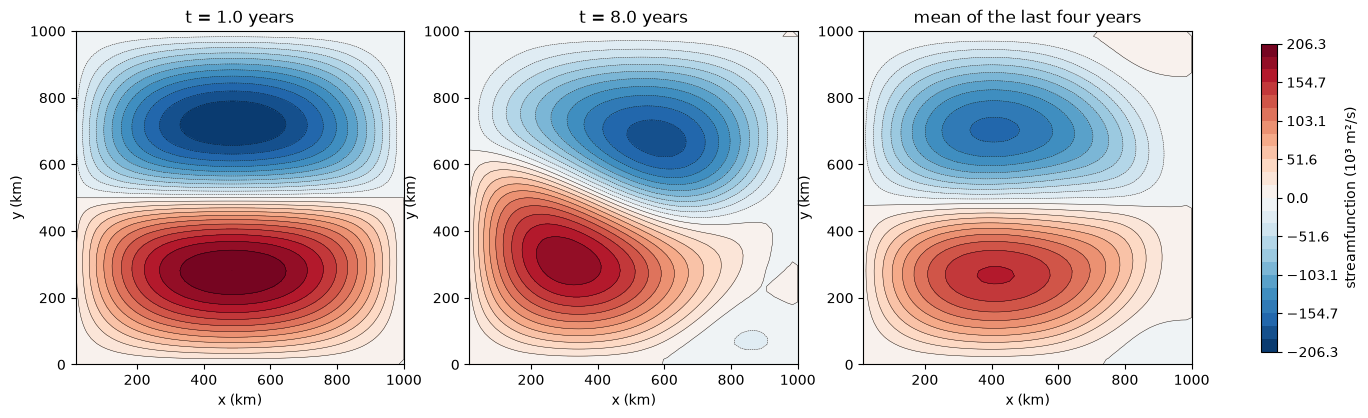

In [7]:
# Shapes: N_Ωx,x = 64 columns; N_Ωx,y + 1 = 65 rows of corners

# the corners: xᵢ = i Δx, yⱼ = j Δy
x_km = jnp.arange(1, num_cells + 1) * spacing / 1e3  # → (N_Ωx,x,)
y_km = jnp.arange(num_cells + 1) * spacing / 1e3  # → (N_Ωx,y + 1,)
one_year = int(jnp.argmin(jnp.abs(years - 1.0)))
panels = [
    (psi[one_year], f"t = {float(years[one_year]):.1f} years"),
    (psi[-1], f"t = {float(years[-1]):.1f} years"),
    (einx.mean("[time] y x -> y x", psi[late]), "mean of the last four years"),
]
largest = max(float(jnp.max(jnp.abs(field))) for field, _ in panels) / 1e3
levels = jnp.linspace(-largest, largest, 25)
mean_psi = panels[2][0]  # → (N_Ωx,y + 1) × N_Ωx,x
mean_asymmetry = jnp.sqrt(
    einx.sum("[y x] ->", (mean_psi + mean_psi[::-1]) ** 2)
    / einx.sum("[y x] ->", mean_psi**2)
)
print(f"Asymmetry of the mean: {float(mean_asymmetry):.2f}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (field, title) in zip(axes, panels, strict=True):
    filled = ax.contourf(x_km, y_km, field / 1e3, levels=levels, cmap="RdBu_r")
    ax.contour(x_km, y_km, field / 1e3, levels=levels, colors="k", linewidths=0.3)
    ax.set_title(title)
    ax.set_xlabel("x (km)")
    ax.set_ylabel("y (km)")
    ax.set_aspect("equal")
plt.colorbar(filled, ax=axes, shrink=0.8, label="streamfunction (10³ m²/s)")
plt.show()

After one year the gyres are mirror images. After eight the line between them no longer follows the middle latitude but slopes from the north-west to the south-east. Their mean over the last four years is closer to a mirror pair, with an asymmetry of 0.20, but it is not one.

## 5. Where are the eddies?

A meandering jet that sheds eddies needs a western boundary current that is barotropically unstable, and at this wind, basin and viscosity it is not. somax's version of this page used a wind of $2 \times 10^{-11}$, twenty times this one, at a time step of 600 s; we measured on this model that over three years the currents then reach 22 m/s and the mean kinetic energy swings between 1.4 and 61 m²/s² within months, which is no ocean either.

The config [`doublegyre_bt_qg_hires.yaml`](https://github.com/jejjohnson/sesmax/blob/main/packages/sesmax-ocean/configs/doublegyre_bt_qg_hires.yaml) of `sesmax-ocean` is the eddying one: a basin of 4000 km on 256² cells, a wind of $4 \times 10^{-12}$ and three times the drag, for five years at 600 s, which is 263 000 steps on sixteen times the cells of this page. Its header comments say how its numbers were chosen. With `sesmax-experiment` installed, it runs from the root of the repository with

```bash
sesmax-experiment simulate --config packages/sesmax-ocean/configs/doublegyre_bt_qg_hires.yaml --output-dir runs/doublegyre_bt_qg_hires
```

## Summary

| Concept | sesmax API |
| --- | --- |
| Create the model | `BarotropicQG.create(nx, ny, Lx, Ly, ..., wind_profile="doublegyre")` |
| Start from a small perturbation | `BarotropicQGState(q=...)` |
| Check the boundary layer | `check_munk_width(None, model)` |
| Streamfunction, velocity and energy of a run | `jax.vmap(model.diagnose)(states)` |
| A long run from a config | `sesmax-experiment simulate --config ...` |

- The wind's curl is odd about the middle latitude, so a flow of two mirror-image gyres solves the equations, but it need not be stable.
- Here that pair is unstable: a perturbation grows by a factor $e$ every 69 days, and after two years the gyres settle into an asymmetric state whose energy is steady to about 1 %.